In [1]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.motivating_example import MotivatingExample

import torch
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt

$$
\mathbb P(M=0 \mid X=x) = \frac{p (X=x \mid M=0) \mathbb P(M=0)}{p(x)}
$$

### Estimate $p(X)$, $\mathbb P (M=\mathbf0)$ and $p(X \mid M=\mathbf0)$ on train data

In [2]:
me = MotivatingExample() # MAR by default
Xtrain = me.get_X()
Mtrain = me.get_M(Xtrain)

# estimate phat(X)
g1 = GaussianMixtureMAR(k_range=(0,10))
g1.fit(Xtrain, Mtrain) # phat(X)

# estimate Phat(M=0)
pmhat = (Mtrain==1).all(dim=1).sum()/me.n

# Estimate phat(X|M=0)
g2 = GaussianMixtureMAR(k_range=(0,10))
g2.fit(Xtrain[(Mtrain==1).all(dim=1)], Mtrain[(Mtrain==1).all(dim=1)])

### Evaluate on test data with $X_1$ fixed

In [3]:
X1test = torch.distributions.Normal(0,1).sample() * torch.ones(me.n, device=me.device)
X2test = me._conditional(X1test)
Xtest = torch.stack([X1test, X2test], dim=1)

In [4]:
logpx = g1.log_prob_x(Xtest)
logpxm0 = g2.log_prob_x(Xtest)
pme = ((logpxm0 - logpx).exp() * pmhat).flatten()

In [5]:
norm = torch.distributions.Normal(0., 1.)
truth = (norm.cdf(X1test) + norm.cdf(X2test)) / 3

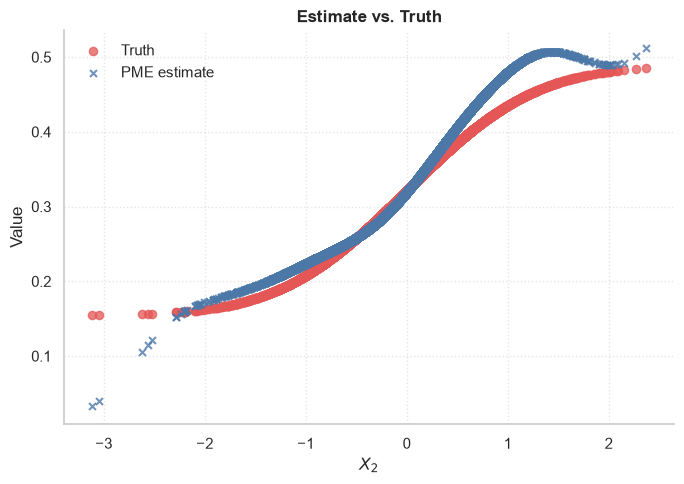

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    X2test, truth,
    s=35,
    color="#E45756",
    alpha=0.75,
    marker="o",
    label="Truth",
    zorder=2,
)

ax.scatter(
    X2test, pme,
    s=25,
    color="#4C78A8",
    alpha=0.8,
    marker="x",
    linewidths=1.5,
    label="PME estimate",
    zorder=3,
)

ax.set_xlabel(r"$X_2$")
ax.set_ylabel("Value")
ax.set_title("Estimate vs. Truth", fontweight="bold")
ax.legend(frameon=False)
ax.grid(True, linestyle=":", alpha=0.5)

sns.despine()
plt.tight_layout()
plt.savefig('results/propensityscoreest.png',dpi=300,
    bbox_inches="tight",)
plt.show()

# compare by difference error

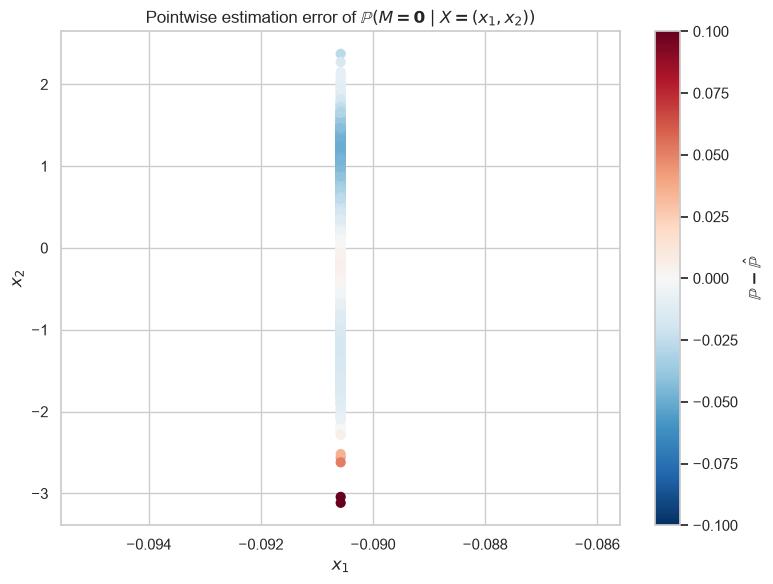

In [7]:
error = (truth - pme).detach().cpu().numpy()
limit = 0.1

fig, ax = plt.subplots(figsize=(8, 6))


sc = ax.scatter(
    X1test.detach().cpu().numpy() if isinstance(X1test, torch.Tensor) else X1test,
    X2test.detach().cpu().numpy() if isinstance(X2test, torch.Tensor) else X2test,
    c=error,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    s=40
)

fig.colorbar(sc, ax=ax, label=r"$\mathbb{P}-\hat \mathbb{P}$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")

ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
plt.tight_layout()
plt.show()

# Compare by ratio to the truth

In [8]:
error = (Zhat / Z).detach().cpu().numpy()
limit = 0.3

fig, ax = plt.subplots(figsize=(8, 6))


sc = ax.scatter(
    X1p.detach().cpu().numpy() if isinstance(X1p, torch.Tensor) else X1p,
    X2p.detach().cpu().numpy() if isinstance(X2p, torch.Tensor) else X2p,
    c=error,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=1-limit, vcenter=1, vmax=1+limit),
    s=40
)

fig.colorbar(sc, ax=ax, label="ratio to the truth")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")

ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
plt.tight_layout()
plt.show()

NameError: name 'Zhat' is not defined